# 项目1｜EEG频谱与频段功率分析

作品集定位：展示你能从真实 EEG 数据完成“读取 → 质检 → 滤波 → PSD → 频段特征 → CSV交付”的完整流程。
适合展示给：科研团队、BCI团队、EEG数据分析客户。


In [2]:
# Cell 1：导入库与基础设置
# 说明：
# - MNE：专门用于 EEG/MEG 神经信号分析
# - NumPy：数值计算
# - Pandas：表格与特征整理
# - Matplotlib：绘图
# - Scikit-learn：后续做机器学习分类
#
# 如果某个库没有安装，再单独安装，不要重复安装整个 Anaconda。

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("MNE版本：", mne.__version__)


MNE版本： 1.12.1


## Cell 2：下载并读取一个轻量真实 EEG 数据
本项目使用 PhysioNet EEG Motor Movement/Imagery 数据中的一个受试者、一个 run。重点不是研究这个人的结论，而是学习一套可复用的 EEG 服务分析流程。

In [3]:
# Cell 2：下载并读取轻量真实 EEG
# subjects=[1]：第1位受试者
# runs=[6]：只下载一个run，减少等待时间
# path：把数据放到当前项目文件夹的 eeg_data 目录

data_path = mne.datasets.eegbci.load_data(
    subjects=[1],
    runs=[6],
    path="./eeg_data"
)

print("下载/读取到的文件：", data_path)

raw = mne.io.read_raw_edf(data_path[0], preload=True, verbose=False)

print(raw)
print("采样率：", raw.info["sfreq"], "Hz")
print("通道数：", len(raw.ch_names))
print("前10个通道：", raw.ch_names[:10])


下载/读取到的文件： [WindowsPath('eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R06.edf')]
<RawEDF | S001R06.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>
采样率： 160.0 Hz
通道数： 64
前10个通道： ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..']


## Cell 3：只保留 EEG 通道并查看原始波形
服务交付中，第一步通常是确认数据规模、通道、采样率和波形是否正常。

EEG通道数： 64
EEG通道： ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']
Using matplotlib as 2D backend.


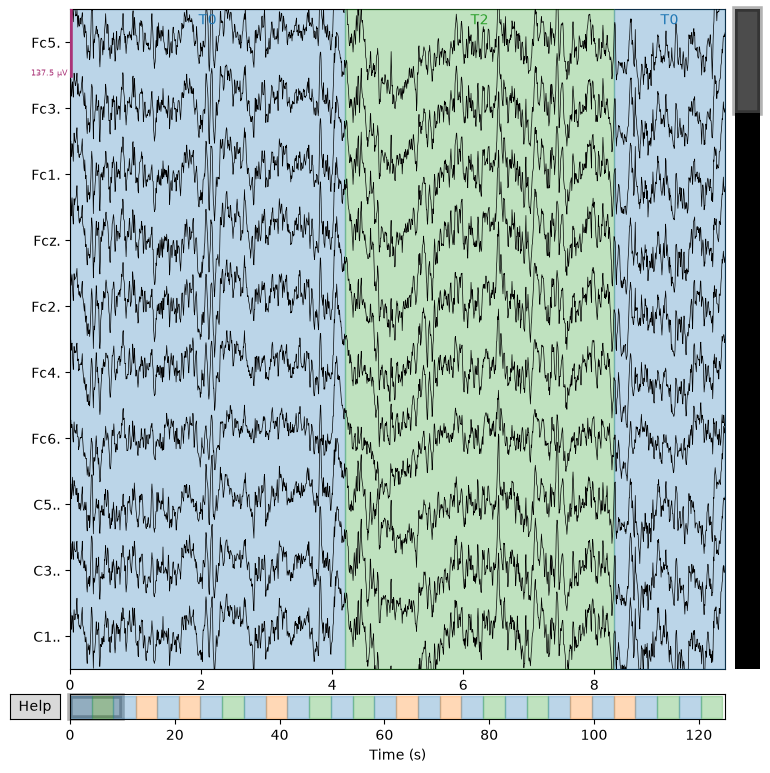

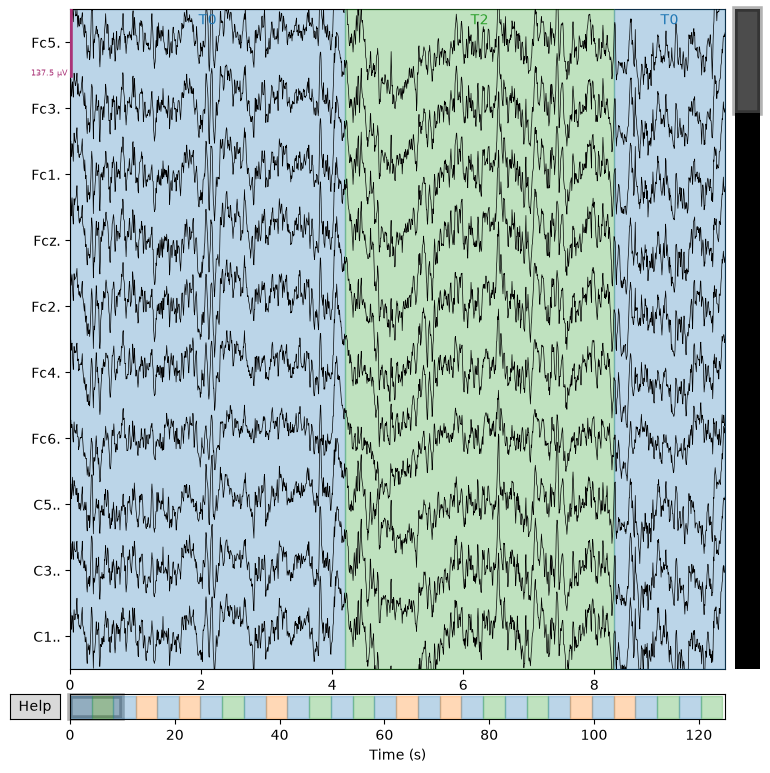

In [4]:
# Cell 3：保留EEG通道并快速质检
raw_eeg = raw.copy().pick("eeg")

print("EEG通道数：", len(raw_eeg.ch_names))
print("EEG通道：", raw_eeg.ch_names)

# 显示前10个通道的10秒波形
raw_eeg.plot(
    duration=10,
    n_channels=min(10, len(raw_eeg.ch_names)),
    scalings="auto"
)


## Cell 4：1–40 Hz 带通滤波
说明：这里是教学/通用分析设置，不代表所有项目都应该固定使用1–40 Hz。实际服务要根据研究问题、电极、采样率和伪迹情况决定。

In [5]:
# Cell 4：复制原始数据后做1–40 Hz带通滤波
raw_filtered = raw_eeg.copy()

raw_filtered.filter(
    l_freq=1,
    h_freq=40,
    verbose=False
)

print("滤波完成")


滤波完成


## Cell 5：计算 PSD
PSD 用来回答：不同频率成分在 EEG 中有多强。

Plotting power spectral density (dB=True).


C:\Users\Administrator\AppData\Local\Temp\ipykernel_12016\2297542457.py:9: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  spectrum.plot()
E:\anacona\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


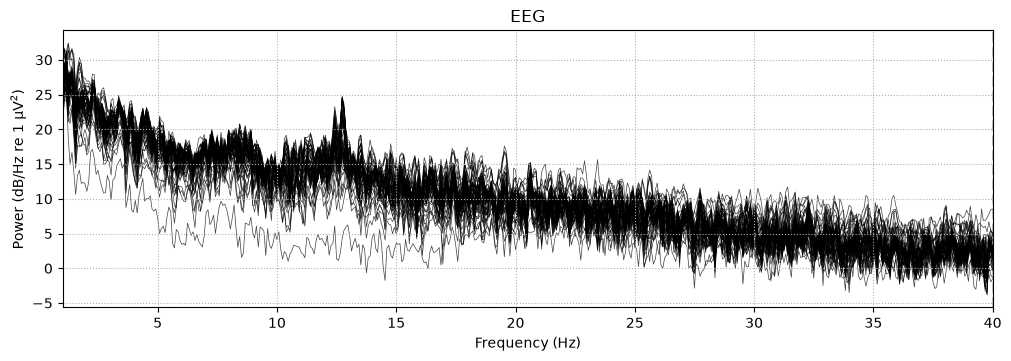

In [6]:
# Cell 5：计算1–40 Hz功率谱密度
spectrum = raw_filtered.compute_psd(
    fmin=1,
    fmax=40,
    verbose=False
)

# MNE自带的频谱图
spectrum.plot()


## Cell 6：计算 Delta/Theta/Alpha/Beta 功率
这一步开始把“图”变成可以交付或进入机器学习的数字特征。

In [7]:
# Cell 6：计算每个通道的频段平均功率
bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
}

psds, freqs = spectrum.get_data(return_freqs=True)

band_power = {}

for band, (fmin, fmax) in bands.items():
    mask = (freqs >= fmin) & (freqs < fmax)
    band_power[band] = psds[:, mask].mean(axis=1)

band_power_df = pd.DataFrame(
    band_power,
    index=raw_filtered.ch_names
)

print(band_power_df.head())


             Delta         Theta         Alpha          Beta
Fc5.  2.082910e-10  5.473757e-11  3.993478e-11  9.608286e-12
Fc3.  2.303278e-10  6.141945e-11  5.271554e-11  1.103314e-11
Fc1.  2.458595e-10  6.782797e-11  4.879957e-11  1.143063e-11
Fcz.  2.483729e-10  7.357154e-11  4.612988e-11  1.161195e-11
Fc2.  2.381640e-10  6.288997e-11  4.645427e-11  1.023761e-11


## Cell 7：输出服务型结果表
实际交付时，不要只给客户一张图；应该给结构化 CSV/Excel，说明每个通道的频段特征。

In [8]:
# Cell 7：整理成可交付的CSV
band_power_df.index.name = "Channel"
band_power_df.to_csv("./band_power_by_channel.csv", encoding="utf-8-sig")

print("已生成：band_power_by_channel.csv")


已生成：band_power_by_channel.csv


## Cell 8：做一个简单的结果图
展示不同频段在各通道上的相对变化。这里只做可视化，不把它解释成临床诊断。

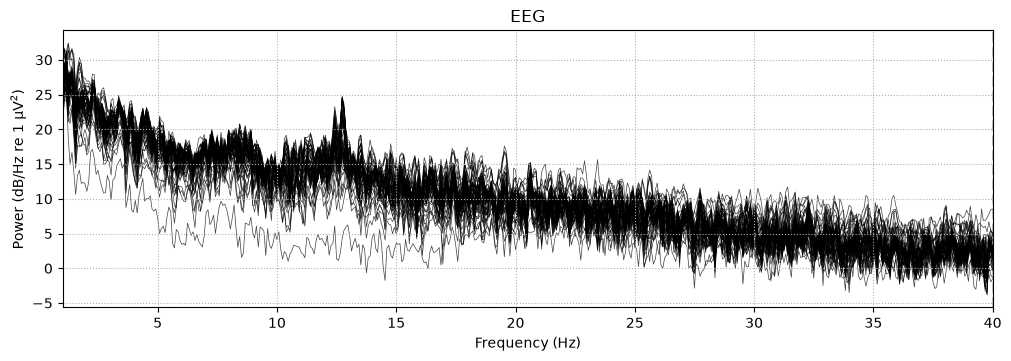

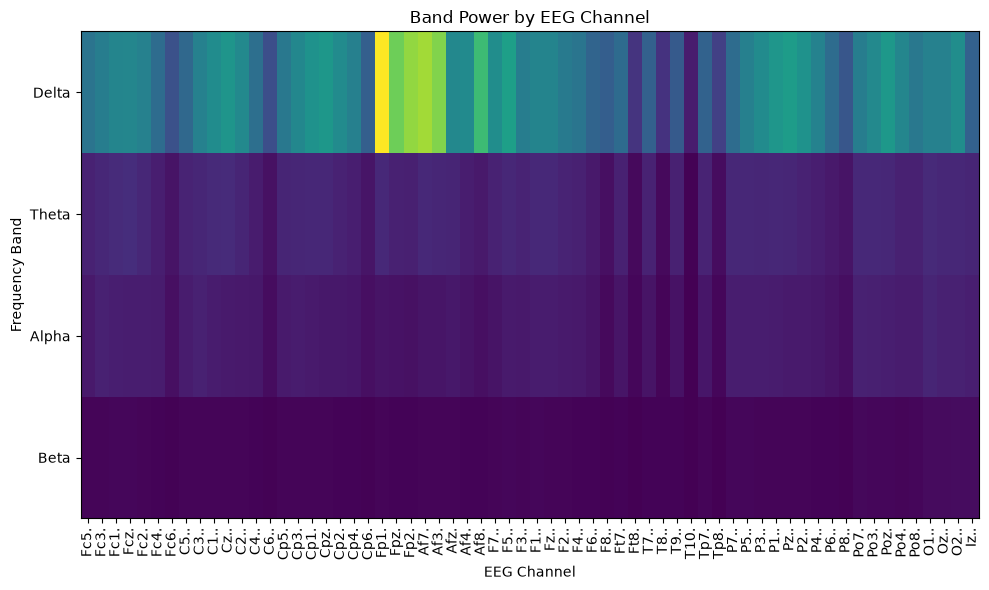

In [9]:
# Cell 8：绘制频段功率矩阵
plt.figure(figsize=(10, 6))
plt.imshow(
    band_power_df.T,
    aspect="auto",
    interpolation="nearest"
)

plt.yticks(range(len(band_power_df.columns)), band_power_df.columns)
plt.xticks(
    range(len(band_power_df.index)),
    band_power_df.index,
    rotation=90
)

plt.xlabel("EEG Channel")
plt.ylabel("Frequency Band")
plt.title("Band Power by EEG Channel")
plt.tight_layout()
plt.show()


In [10]:
#查看eeg的通道编号和名称
#Python从0开始，0代表第一个通道
for i,name in enumerate(raw_filtered.ch_names[:10]):
    print(i,name)

0 Fc5.
1 Fc3.
2 Fc1.
3 Fcz.
4 Fc2.
5 Fc4.
6 Fc6.
7 C5..
8 C3..
9 C1..


In [11]:
#选择第一个eeg通道的psd

channel = 0
channel_psd = psds[channel]
print("通道",raw_filtered.ch_names[channel])
print("psd数据点数量",len(channel_psd))
print("频率范围",freqs[0],"到",freqs[-1],"Hz")

通道 Fc5.
psd数据点数量 500
频率范围 1.015625 到 40.0 Hz


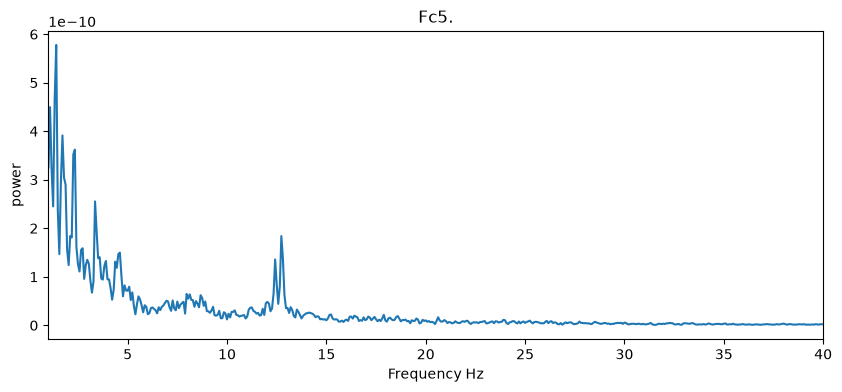

In [12]:
#查看第一个通道的频谱
plt.figure(figsize=(10,4))
plt.plot(freqs,channel_psd)
plt.xlim(1,40)
plt.xlabel("Frequency Hz")
plt.ylabel("power")
plt.title(raw_filtered.ch_names[channel])
plt.show()

In [13]:
#定义主要的五个频段
bands = {
    "Delta":(1,4),
    "Theta":(4,8),
    "Alpha":(8,13),
    "Beta":(13,30),
    "Gamma":(30,40)
}
print(bands)

{'Delta': (1, 4), 'Theta': (4, 8), 'Alpha': (8, 13), 'Beta': (13, 30), 'Gamma': (30, 40)}


In [14]:
#计算第一个通道的每个频段的平均功率
band_power = {}
for band,(fmin,fmax) in bands.items():
    #找到这个频段的所属位置
    mask=(freqs>=fmin)&(freqs<fmax)
    #计算这个频段的平均psd
    band_power[band] =channel_psd[mask].mean()
print(band_power)

{'Delta': np.float64(2.082910444019053e-10), 'Theta': np.float64(5.473757234381774e-11), 'Alpha': np.float64(3.993478316624658e-11), 'Beta': np.float64(9.608285622958303e-12), 'Gamma': np.float64(2.3446054215996594e-12)}


In [15]:
#把频段功率整理成表格
feature_df = pd.DataFrame(
    [band_power],
    index=[raw_filtered.ch_names[channel]]
)
print(feature_df)

             Delta         Theta         Alpha          Beta         Gamma
Fc5.  2.082910e-10  5.473757e-11  3.993478e-11  9.608286e-12  2.344605e-12


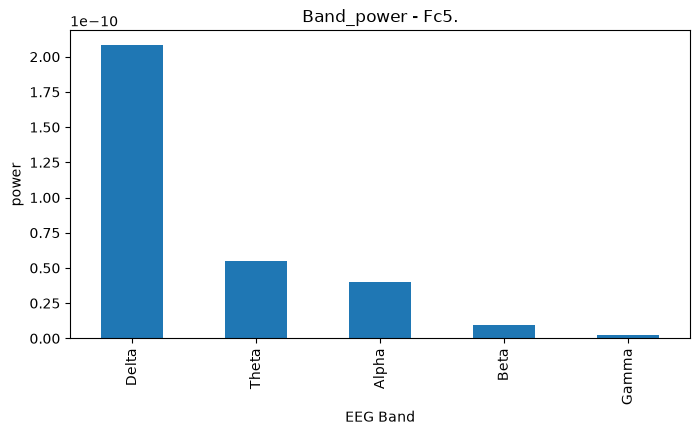

In [16]:
#可视化不同频段功率
feature_df.T.plot(
    kind = "bar",
    legend =False,
    figsize = (8,4)
)
plt.xlabel("EEG Band")
plt.ylabel("power")
plt.title(f"Band_power - {raw_filtered.ch_names[channel]}")
plt.show()

In [17]:
#计算所有eeg通道的Delta,Theta,Alpha,Beta,Gamma功率
band_power_all = {}
for band,(fmin,fmax) in bands.items():
    #找出当前频段对应频率
    mask =(freqs>=fmin)&(freqs<fmax)

    #对每个通道，在该频段内求平均功率
    band_power_all[band] = psds[:,mask].mean(axis=1)
print("计算完成")

计算完成


In [18]:
#把所有通道的频段功率整理成dataframe
feature_df = pd.DataFrame(
    band_power_all,
    index = raw_filtered.ch_names
)
print("特征矩阵大小",feature_df.shape)
feature_df.head()

特征矩阵大小 (64, 5)


,Delta,Theta,Alpha,Beta,Gamma
Fc5.,2.082910e-10,5.473757e-11,3.993478e-11,9.608286e-12,2.344605e-12
Fc3.,2.303278e-10,6.141945e-11,5.271554e-11,1.103314e-11,2.308851e-12
Fc1.,2.458595e-10,6.782797e-11,4.879957e-11,1.143063e-11,2.501664e-12
Fcz.,2.483729e-10,7.357154e-11,4.612988e-11,1.161195e-11,2.636238e-12
Fc2.,2.381640e-10,6.288997e-11,4.645427e-11,1.023761e-11,2.243055e-12


In [20]:
#找出alpha功率最高的10个通道
alpha_top10 = feature_df['Alpha'].sort_values(
    ascending = False
).head(10)
print(alpha_top10)

O1..    5.839625e-11
Fc3.    5.271554e-11
C3..    5.207418e-11
Oz..    5.206375e-11
Po7.    5.196184e-11
O2..    5.175705e-11
Po3.    5.073767e-11
Fc1.    4.879957e-11
Poz.    4.763507e-11
Iz..    4.724240e-11
Name: Alpha, dtype: float64


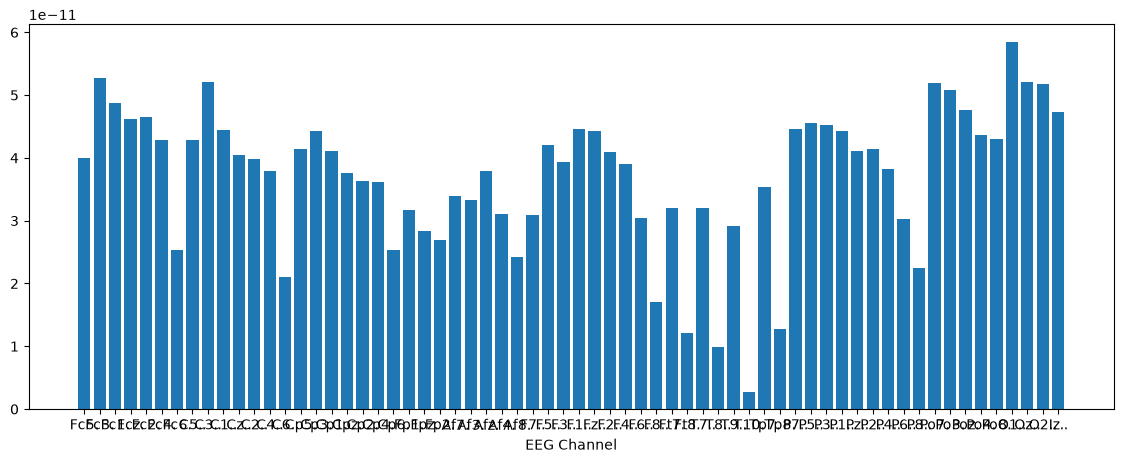

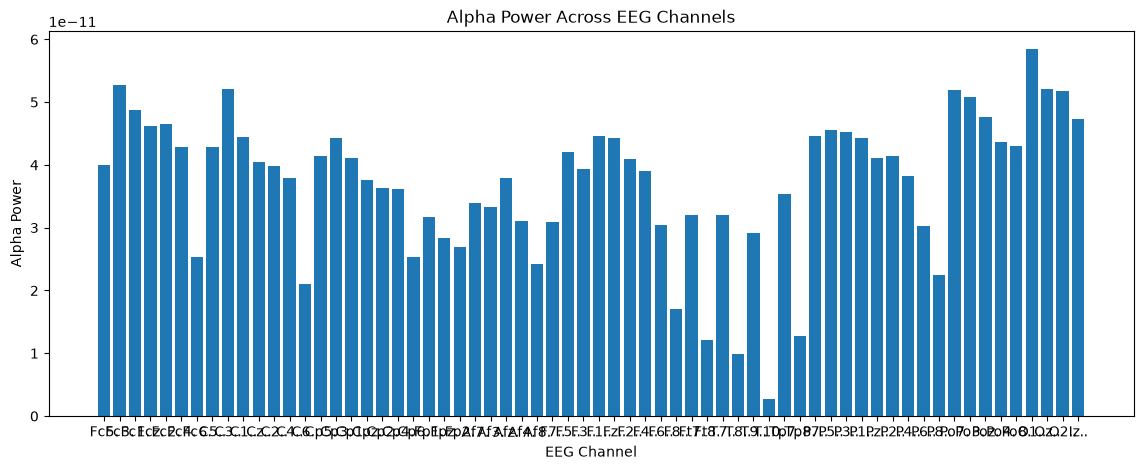

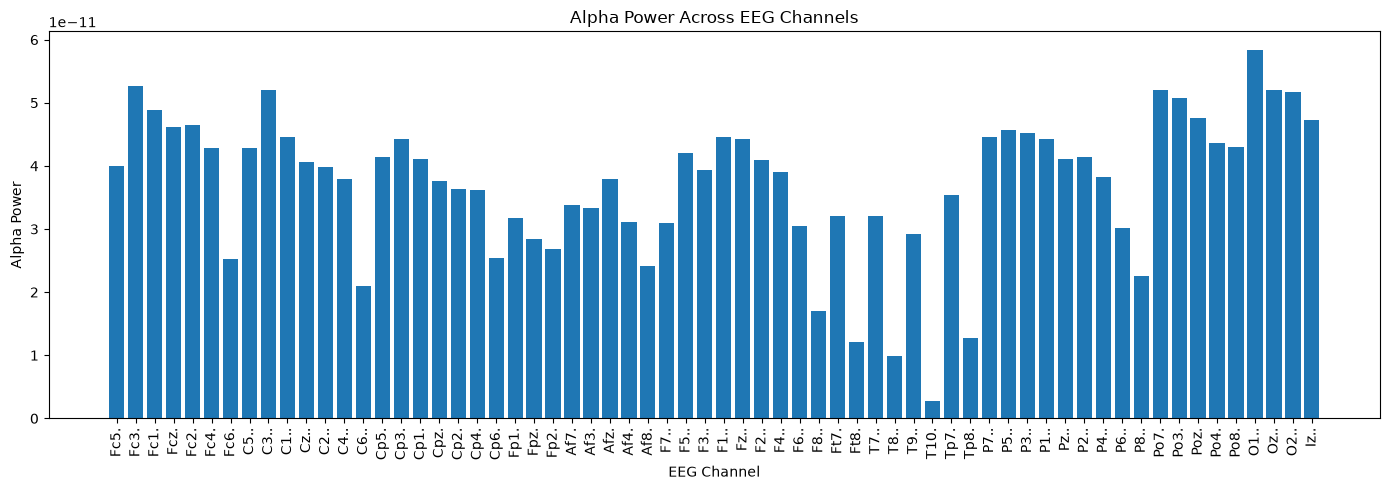

In [23]:
#绘制所有eeg通道的alpha功率
plt.figure(figsize=(14,5))
plt.bar(
    feature_df.index,
    feature_df["Alpha"]
)

plt.xlabel("EEG Channel")
plt.ylabel("Alpha Power")
plt.title("Alpha Power Across EEG Channels")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [30]:
#计算每个通道各频段的相对功率
bands_list = ["Delta","Theta","Alpha","Beta","Gamma"]
#计算每个通道的总功率
total_power = feature_df[band_list].sum(axis=1)
#计算相对功率
relative_power_df = feature_df[bands_list].div(total_power,axis=0)
print("相对功率计算完成")
relative_power_df.head()

相对功率计算完成


,Delta,Theta,Alpha,Beta,Gamma
Fc5.,0.661417,0.173816,0.126811,0.030511,0.007445
Fc3.,0.643725,0.171656,0.147330,0.030836,0.006453
Fc1.,0.653153,0.180193,0.129642,0.030367,0.006646
Fcz.,0.649642,0.192433,0.120657,0.030372,0.006895
Fc2.,0.661587,0.174700,0.129044,0.028439,0.006231


In [31]:
#检查每个通道相对功率之和是否等于1
check = relative_power_df.sum(axis=1)
print(check.head())
print("最大误差",abs(check-1).max())

Fc5.    1.0
Fc3.    1.0
Fc1.    1.0
Fcz.    1.0
Fc2.    1.0
dtype: float64
最大误差 3.3306690738754696e-16


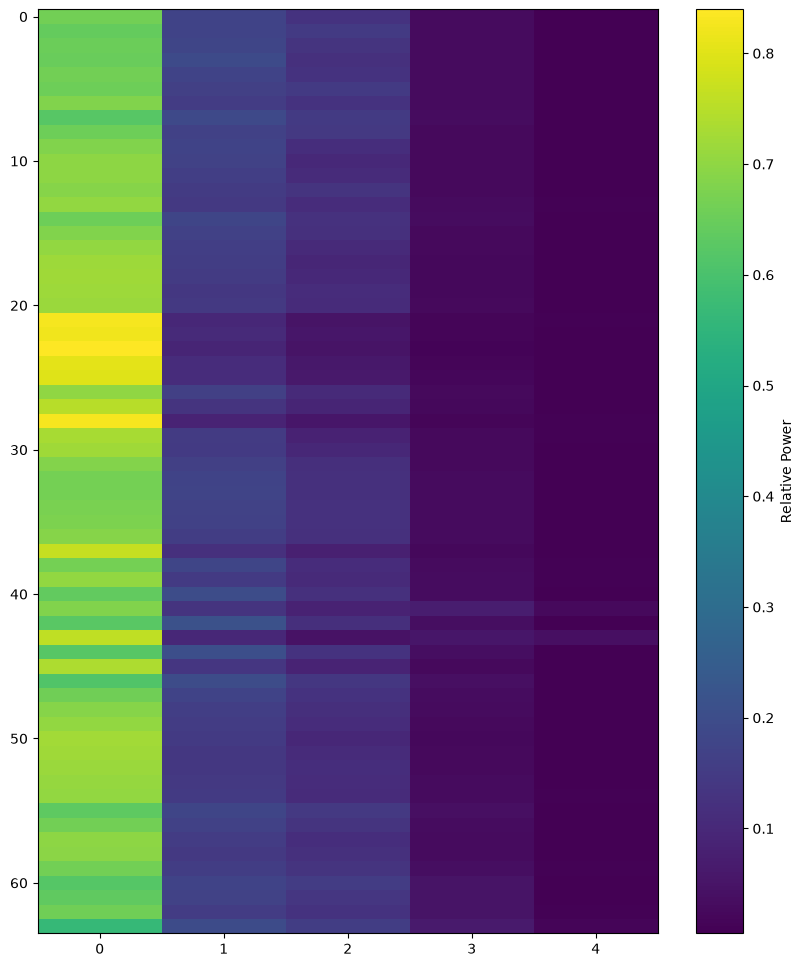

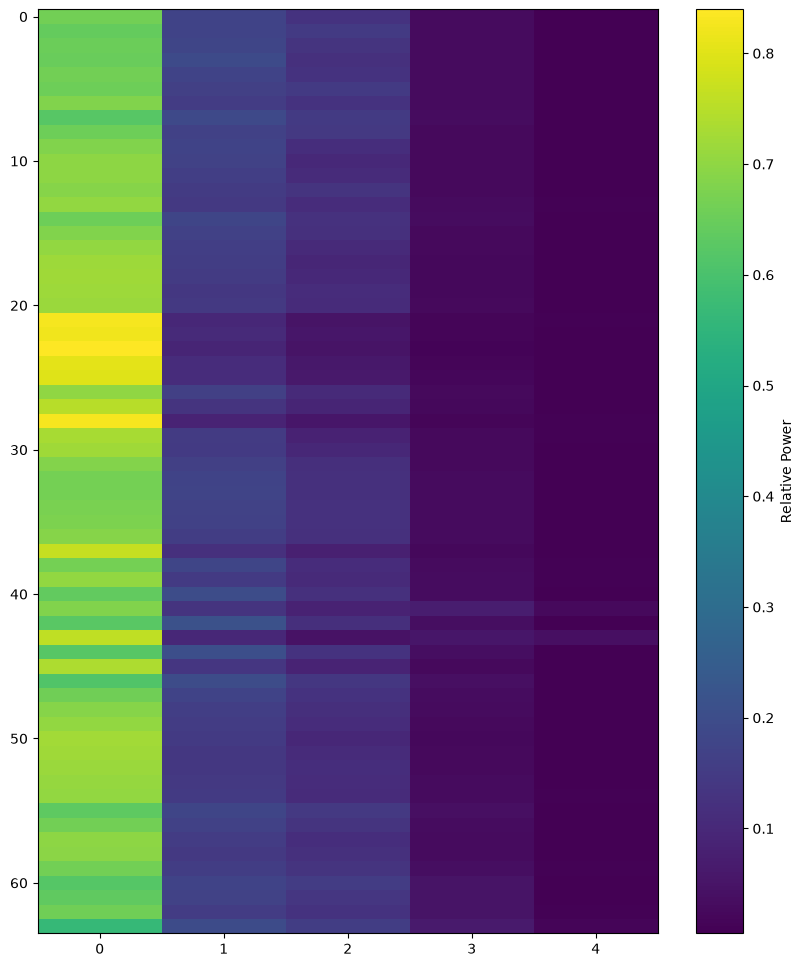

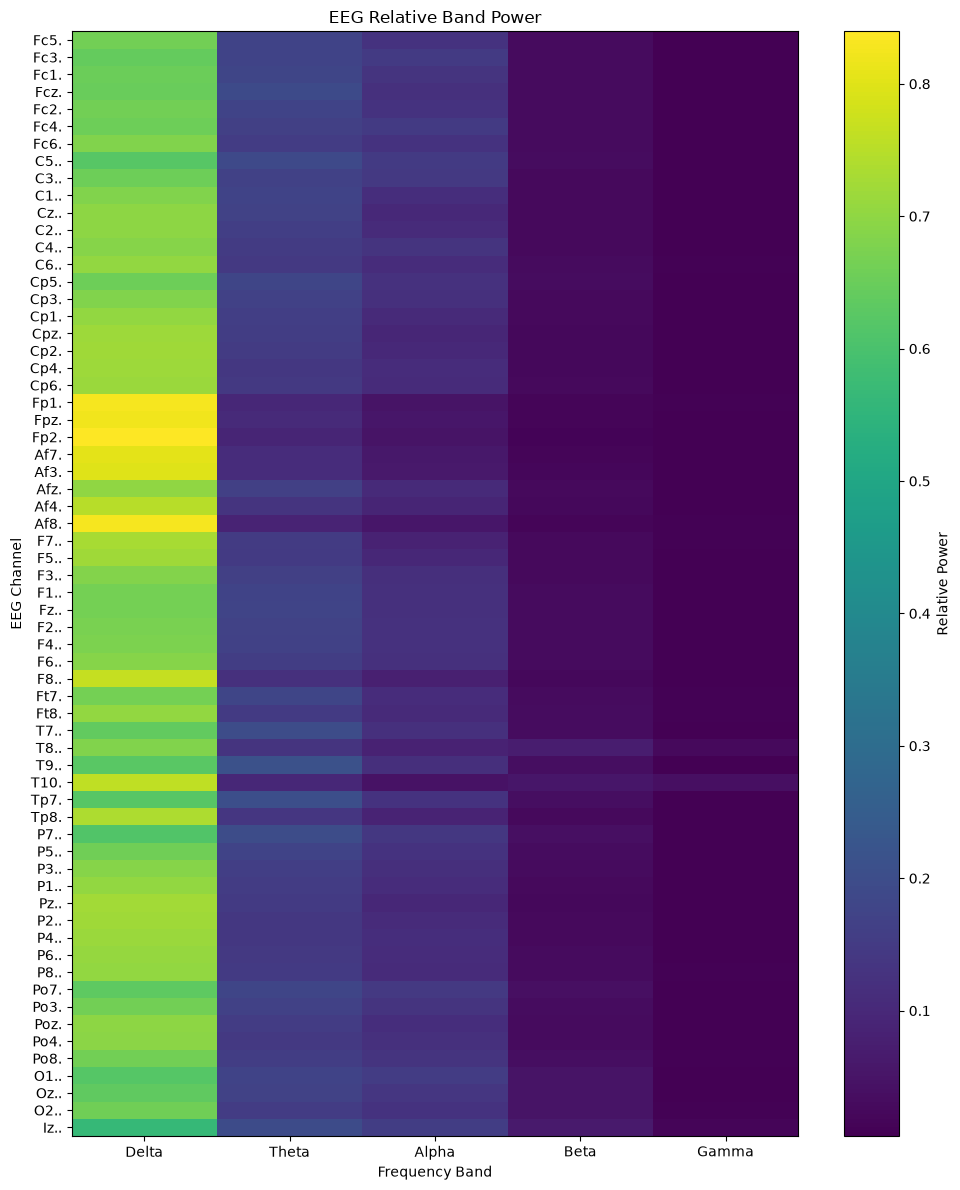

In [32]:
# Cell 14：绘制 64 个 EEG 通道的频段相对功率热力图

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 12))

plt.imshow(
    relative_power_df.values,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Relative Power")

plt.xticks(
    range(len(bands_list)),
    bands_list
)

plt.yticks(
    range(len(relative_power_df)),
    relative_power_df.index
)

plt.xlabel("Frequency Band")
plt.ylabel("EEG Channel")
plt.title("EEG Relative Band Power")

plt.tight_layout()
plt.show()

In [33]:
# Cell 15：计算 64 个通道的平均相对功率

mean_relative_power = relative_power_df.mean(axis=0)

print(mean_relative_power)

Delta    0.694004
Theta    0.156191
Alpha    0.111229
Beta     0.030445
Gamma    0.008130
dtype: float64


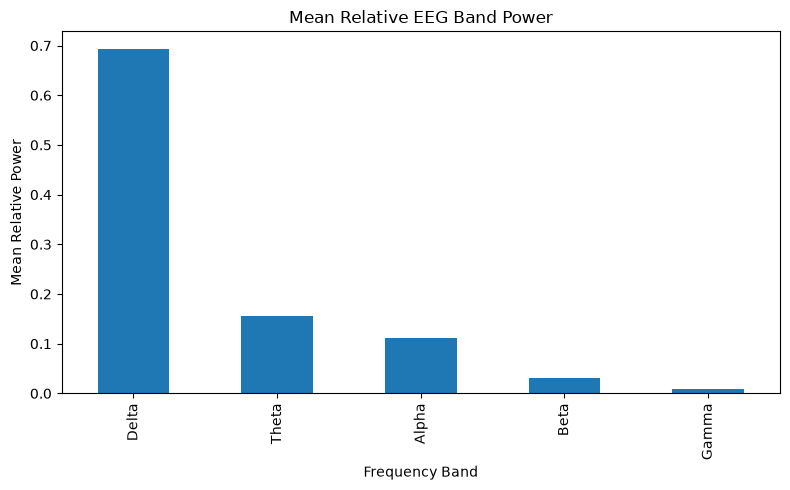

In [34]:
# Cell 16：绘制平均频段相对功率

plt.figure(figsize=(8, 5))

mean_relative_power.plot(kind="bar")

plt.xlabel("Frequency Band")
plt.ylabel("Mean Relative Power")
plt.title("Mean Relative EEG Band Power")

plt.tight_layout()
plt.show()

In [35]:
# Cell 17：创建结果文件夹

import os

os.makedirs("./results", exist_ok=True)
os.makedirs("./figures", exist_ok=True)

print("结果文件夹创建完成")

结果文件夹创建完成


In [36]:
# Cell 18：保存绝对频段特征

feature_df.to_csv(
    "./results/band_power_absolute.csv",
    encoding="utf-8-sig"
)

print("绝对频段功率已保存")

绝对频段功率已保存


In [37]:
# Cell 19：保存相对频段功率

relative_power_df.to_csv(
    "./results/band_power_relative.csv",
    encoding="utf-8-sig"
)

print("相对频段功率已保存")

相对频段功率已保存


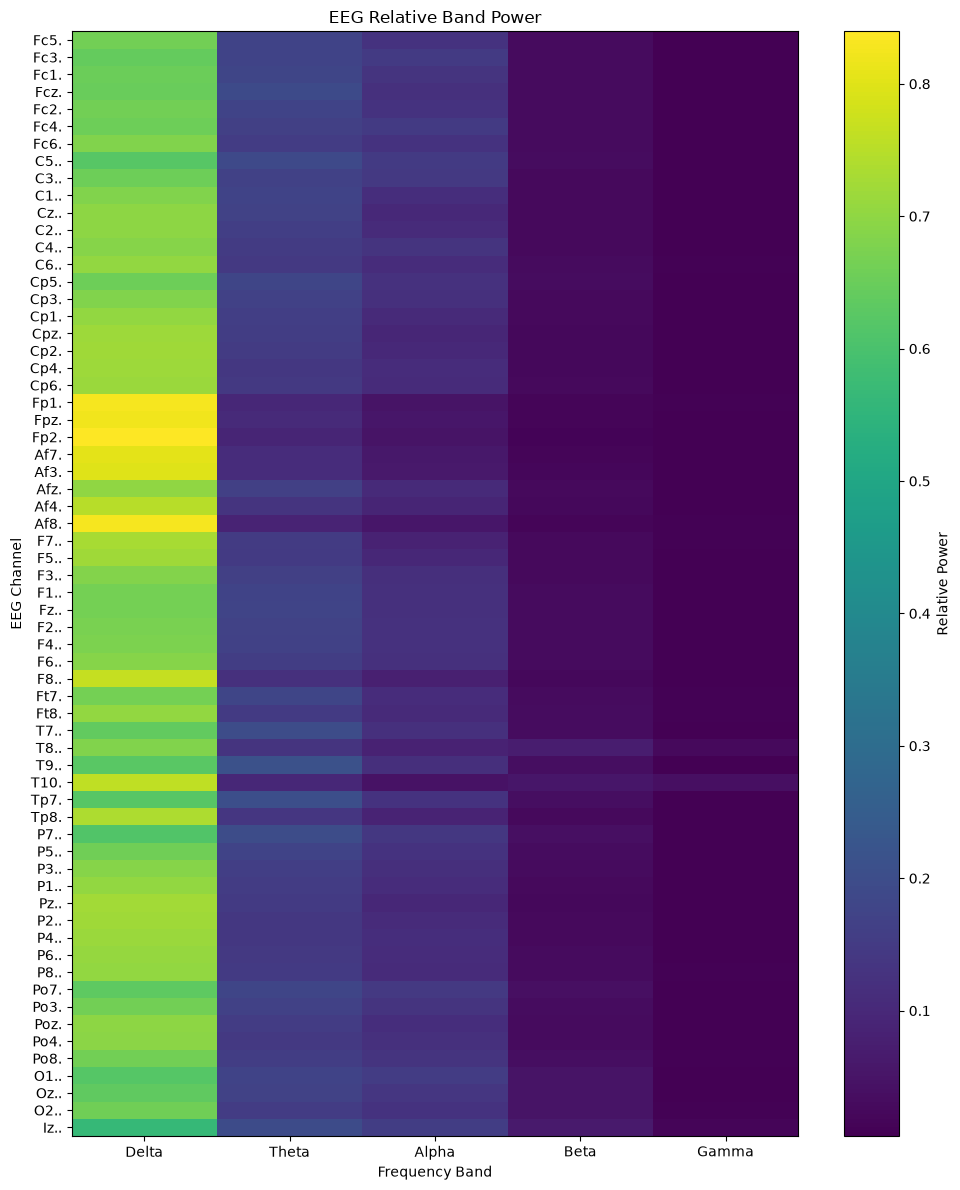

热力图已保存


In [38]:
# Cell 20：保存 EEG 频段相对功率热力图

plt.figure(figsize=(10, 12))

plt.imshow(
    relative_power_df.values,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Relative Power")

plt.xticks(
    range(len(bands_list)),
    bands_list
)

plt.yticks(
    range(len(relative_power_df)),
    relative_power_df.index
)

plt.xlabel("Frequency Band")
plt.ylabel("EEG Channel")
plt.title("EEG Relative Band Power")

plt.tight_layout()

plt.savefig(
    "./figures/eeg_relative_band_power_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("热力图已保存")

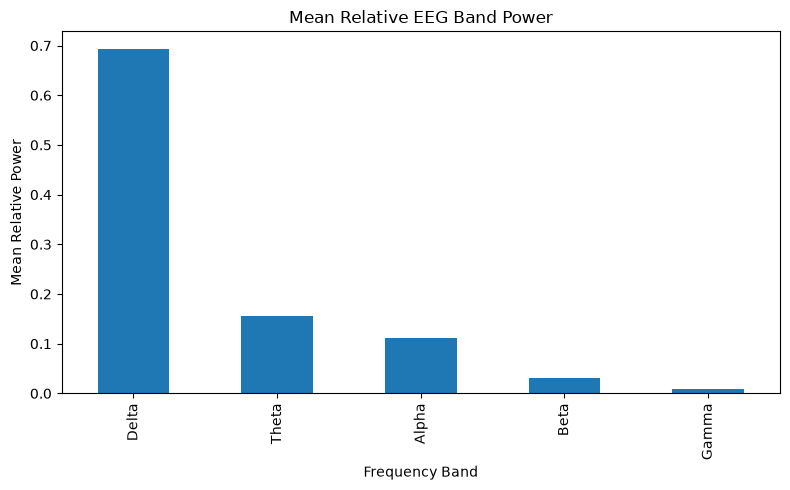

平均频段功率图已保存


In [39]:
# Cell 21：保存平均频段相对功率图

plt.figure(figsize=(8, 5))

mean_relative_power.plot(kind="bar")

plt.xlabel("Frequency Band")
plt.ylabel("Mean Relative Power")
plt.title("Mean Relative EEG Band Power")

plt.tight_layout()

plt.savefig(
    "./figures/mean_relative_band_power.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("平均频段功率图已保存")

In [40]:
# Cell 22：检查最终生成的文件

print("results 文件：")
print(os.listdir("./results"))

print("\nfigures 文件：")
print(os.listdir("./figures"))

results 文件：
['band_power_absolute.csv', 'band_power_relative.csv']

figures 文件：
['eeg_relative_band_power_heatmap.png', 'mean_relative_band_power.png']


In [41]:
# Cell 23：EEG 数据质量检查

import numpy as np

# 采样率
sfreq = raw_eeg.info["sfreq"]

# EEG 通道数量
n_channels = len(raw_eeg.ch_names)

# 数据采样点数量
n_samples = raw_eeg.n_times

# 数据时长（秒）
duration = n_samples / sfreq

# 获取 EEG 数据
data = raw_eeg.get_data()

# 检查 NaN
nan_count = np.isnan(data).sum()

# 检查 Inf
inf_count = np.isinf(data).sum()

print("===== EEG 数据质量报告 =====")
print(f"采样率：{sfreq:.2f} Hz")
print(f"EEG 通道数：{n_channels}")
print(f"采样点数：{n_samples}")
print(f"数据时长：{duration:.2f} 秒")
print(f"NaN 数量：{nan_count}")
print(f"Inf 数量：{inf_count}")

===== EEG 数据质量报告 =====
采样率：160.00 Hz
EEG 通道数：64
采样点数：20000
数据时长：125.00 秒
NaN 数量：0
Inf 数量：0


In [42]:
# Cell 24：检查每个 EEG 通道的信号幅度

channel_std = np.std(data, axis=1)

qc_channel_df = pd.DataFrame({
    "Channel": raw_eeg.ch_names,
    "STD": channel_std
})

print(qc_channel_df.head(10))

  Channel       STD
0    Fc5.  0.000069
1    Fc3.  0.000071
2    Fc1.  0.000070
3    Fcz.  0.000070
4    Fc2.  0.000067
5    Fc4.  0.000060
6    Fc6.  0.000058
7    C5..  0.000065
8    C3..  0.000065
9    C1..  0.000066


In [43]:
# Cell 25：保存 EEG 数据质量报告

qc_summary = pd.DataFrame({
    "Item": [
        "Sampling Rate (Hz)",
        "EEG Channels",
        "Samples",
        "Duration (s)",
        "NaN Count",
        "Inf Count"
    ],
    "Value": [
        sfreq,
        n_channels,
        n_samples,
        duration,
        nan_count,
        inf_count
    ]
})

qc_summary.to_csv(
    "./results/eeg_quality_report.csv",
    index=False,
    encoding="utf-8-sig"
)

print("QC 报告已保存")

QC 报告已保存
